# Weekly price variation

Summarize observed prices by product and sales week, then describe how often weekly modal prices differ from each product's reference price. These are exploratory descriptions of recorded prices and quantities.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

project_root_candidates = (Path.cwd(), *Path.cwd().parents)
project_root = next(
    (candidate for candidate in project_root_candidates if (candidate / "src" / "clean.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root from the current directory.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.clean import load_clean

clean = load_clean(verbose=False)
assert len(clean) == 524894
assert clean["Quantity"].sum() == 5351288
print(f"Clean rows: {len(clean):,}")
print(f"Clean units: {clean['Quantity'].sum():,}")

Clean rows: 524,894
Clean units: 5,351,288


Each row combines one product (`StockCode`) with one week of observed sales.
Units, distinct invoices, and prices summarize that product's activity during that week.
Weeks with no sales for a product are not rows; we do not fill them.

In [2]:
product_week = (
    clean.groupby(["StockCode", "week"], as_index=False)
    .agg(
        units=("Quantity", "sum"),
        invoices=("InvoiceNo", "nunique"),
        n_prices=("UnitPrice", "nunique"),
        line_value=("line_value", "sum"),
        price_min=("UnitPrice", "min"),
        price_max=("UnitPrice", "max"),
    )
)
product_week["price_wavg"] = product_week["line_value"] / product_week["units"]
product_week = product_week.drop(columns="line_value")

weekly_price_counts = (
    clean.groupby(["StockCode", "week", "UnitPrice"], as_index=False)
    .size()
    .rename(columns={"size": "price_frequency"})
    .sort_values(
        ["StockCode", "week", "price_frequency", "UnitPrice"],
        ascending=[True, True, False, True],
    )
    .drop_duplicates(["StockCode", "week"])
    .rename(columns={"UnitPrice": "price_mode"})
    [["StockCode", "week", "price_mode"]]
)
product_week = product_week.merge(
    weekly_price_counts, on=["StockCode", "week"], how="left", validate="one_to_one"
)
product_week = product_week[
    ["StockCode", "week", "units", "invoices", "n_prices", "price_mode", "price_wavg", "price_min", "price_max"]
].sort_values(["StockCode", "week"], ignore_index=True)

assert product_week["units"].sum() == 5351288
print(f"Product-week rows: {len(product_week):,}")
print(f"Distinct invoice counts summed across product-weeks: {product_week['invoices'].sum():,}")
print(f"Product-week table shape: {product_week.shape}")
display(product_week.head())

Product-week rows: 100,068
Distinct invoice counts summed across product-weeks: 514,512
Product-week table shape: (100068, 9)


,StockCode,week,units,invoices,n_prices,price_mode,price_wavg,price_min,price_max
0,10002,2010-11-29,70,7,2,0.85,0.931000,0.85,1.66
1,10002,2010-12-06,138,14,2,0.85,0.920435,0.85,1.66
2,10002,2010-12-13,41,8,2,0.85,0.948780,0.85,1.66
3,10002,2010-12-20,2,1,1,1.66,1.660000,1.66,1.66
4,10002,2011-01-03,73,3,2,0.85,0.861096,0.85,1.66


## Product-weeks with multiple recorded prices

A product-week is mixed when it contains more than one distinct `UnitPrice`.

In [3]:
mixed_price_weeks = product_week.loc[product_week["n_prices"].gt(1)]
mixed_price_share = len(mixed_price_weeks) / len(product_week) * 100
mixed_price_units = int(mixed_price_weeks["units"].sum())
print(f"Product-weeks with multiple prices: {len(mixed_price_weeks):,} / {len(product_week):,} ({mixed_price_share:.2f}%)")
print(f"Units in product-weeks with multiple prices: {mixed_price_units:,}")

Product-weeks with multiple prices: 46,112 / 100,068 (46.08%)
Units in product-weeks with multiple prices: 4,267,571


## Weekly price-mode deviations by product

For each product, the reference price is its most frequent weekly `price_mode`, with ties resolved to the lower price. A week deviates when its mode differs from the reference by at least the threshold shown. The 1%, 5%, and 10% thresholds are exploratory, not final.

In [4]:
reference_prices = (
    product_week.groupby(["StockCode", "price_mode"], as_index=False)
    .size()
    .rename(columns={"size": "mode_frequency"})
    .sort_values(
        ["StockCode", "mode_frequency", "price_mode"],
        ascending=[True, False, True],
    )
    .drop_duplicates("StockCode")
    [["StockCode", "price_mode"]]
    .rename(columns={"price_mode": "reference_price"})
)
product_week_analysis = product_week.merge(
    reference_prices, on="StockCode", how="left", validate="many_to_one"
)
product_week_analysis["active_weeks"] = product_week_analysis.groupby("StockCode")["week"].transform("size")
product_week_analysis["relative_deviation"] = (
    product_week_analysis["price_mode"] / product_week_analysis["reference_price"] - 1
).abs()

product_summary = (
    product_week_analysis.groupby("StockCode", as_index=False)
    .agg(
        active_weeks=("week", "size"),
        reference_price=("reference_price", "first"),
    )
)
eligible_product_count = int(product_summary["active_weeks"].ge(10).sum())
thresholds = {"1%": 0.01, "5%": 0.05, "10%": 0.10}
threshold_results = {"products_active_at_least_10_weeks": eligible_product_count}
deviation_columns = {}
for label, threshold in thresholds.items():
    deviation_column = f"deviating_weeks_{label.replace('%', 'pct')}"
    product_week_analysis[deviation_column] = product_week_analysis["relative_deviation"].ge(threshold)
    deviation_counts = product_week_analysis.groupby("StockCode")[deviation_column].sum()
    product_summary[deviation_column] = product_summary["StockCode"].map(deviation_counts)
    deviation_columns[label] = deviation_column
    result_column = f"products_3plus_deviating_weeks_{label.replace('%', 'pct')}"
    threshold_results[result_column] = int(
        (product_summary["active_weeks"].ge(10) & product_summary[deviation_column].ge(3)).sum()
    )

print(f"Products with at least 10 active weeks: {eligible_product_count:,}")
display(pd.DataFrame([threshold_results]))

Products with at least 10 active weeks: 2,916


,products_active_at_least_10_weeks,products_3plus_deviating_weeks_1pct,products_3plus_deviating_weeks_5pct,products_3plus_deviating_weeks_10pct
0,2916,2134,2004,1969


## Example weekly price-mode series

The first group shows three products with the most weeks deviating by at least 5%. The second shows products active for at least 10 weeks with exactly one such deviating week.

In [5]:
deviating_weeks_5pct = deviation_columns["5%"]
deviations_by_product = product_week_analysis.groupby("StockCode")[deviating_weeks_5pct].sum()
many_deviation_products = (
    product_summary.loc[product_summary["active_weeks"].ge(10)]
    .assign(deviating_weeks_5pct=lambda frame: frame[deviating_weeks_5pct])
    .sort_values(["deviating_weeks_5pct", "StockCode"], ascending=[False, True])
    .head(3)["StockCode"]
    .tolist()
)
one_deviation_products = (
    product_summary.loc[
        product_summary["active_weeks"].ge(10)
        & product_summary[deviating_weeks_5pct].eq(1)
    ]
    .sort_values("StockCode")
    .head(3)["StockCode"]
    .tolist()
)
assert len(many_deviation_products) == 3, "Expected three products with many 5% deviations."
assert len(one_deviation_products) == 3, "Expected three products with exactly one 5% deviation."

def print_price_mode_series(title, stock_codes):
    print(title)
    for stock_code in stock_codes:
        series = (
            product_week_analysis.loc[
                product_week_analysis["StockCode"].eq(stock_code), ["week", "price_mode"]
            ]
            .set_index("week")["price_mode"]
            .sort_index()
        )
        print(f"\nStockCode {stock_code} ({len(series)} active weeks):")
        print(series.to_string())

print_price_mode_series("Three products with the most 5% deviating weeks:", many_deviation_products)
print_price_mode_series("Three products with exactly one 5% deviating week:", one_deviation_products)

Three products with the most 5% deviating weeks:

StockCode 22378 (51 active weeks):
week
2010-11-29    4.21
2010-12-06    4.21
2010-12-13    0.85
2010-12-20    0.85
2011-01-03    1.66
2011-01-10    0.85
2011-01-17    1.63
2011-01-24    0.85
2011-01-31    2.10
2011-02-07    2.10
2011-02-14    2.10
2011-02-21    4.13
2011-02-28    2.10
2011-03-07    2.10
2011-03-14    4.13
2011-03-21    2.10
2011-03-28    4.13
2011-04-04    4.13
2011-04-11    2.10
2011-04-18    4.13
2011-04-25    4.96
2011-05-02    0.85
2011-05-09    2.10
2011-05-16    2.10
2011-05-23    2.10
2011-06-06    4.96
2011-06-13    2.10
2011-06-20    4.13
2011-06-27    1.63
2011-07-04    1.63
2011-07-11    1.63
2011-07-18    1.63
2011-07-25    4.13
2011-08-01    4.13
2011-08-08    4.13
2011-08-15    2.10
2011-08-22    2.10
2011-08-29    4.13
2011-09-05    4.13
2011-09-12    4.13
2011-09-19    4.13
2011-09-26    4.13
2011-10-03    2.10
2011-10-10    2.10
2011-10-24    2.10
2011-10-31    4.13
2011-11-07    4.13
2011-11-14    2.1

## Conclusion

Multiple prices occur in 46,112 of 100,068 product-weeks (46.08%), containing 4,267,571 units. Of 2,916 products active in at least 10 weeks, 2,134, 2,004, and 1,969 meet the three-or-more-deviation rule at 1%, 5%, and 10%, respectively. These are descriptive results only: price and quantity both depend on time of year, bulk buyers, and promotions.

## 6a. Does the share of product-weeks with mixed prices differ by customer-ID presence?

A product-week is assigned to the present or missing group according to whether its contributing rows have a `CustomerID`.

In [6]:
customer_type_product_week = (
    clean.assign(customer_id_present=clean["CustomerID"].notna())
    .groupby(["StockCode", "week", "customer_id_present"], as_index=False)
    .agg(
        line_count=("Quantity", "size"),
        units=("Quantity", "sum"),
        n_prices=("UnitPrice", "nunique"),
    )
)

assert customer_type_product_week["line_count"].sum() == len(clean)
assert customer_type_product_week["units"].sum() == clean["Quantity"].sum()
assert customer_type_product_week.groupby("customer_id_present")["line_count"].sum().sum() == len(clean)
print(f"Customer-type product-week rows reconcile to clean lines: {customer_type_product_week['line_count'].sum():,} = {len(clean):,}")
print(f"Customer-type product-week units reconcile to clean units: {customer_type_product_week['units'].sum():,} = {clean['Quantity'].sum():,}")

customer_mix_results = {}
for customer_id_present, label in [(True, "CustomerID present"), (False, "CustomerID missing")]:
    group = customer_type_product_week.loc[
        customer_type_product_week["customer_id_present"].eq(customer_id_present)
    ]
    mixed = group["n_prices"].gt(1)
    mixed_count = int(mixed.sum())
    total_count = len(group)
    share = mixed_count / total_count * 100
    customer_mix_results[label] = (mixed_count, total_count, share)
    print(f"{label}: {mixed_count:,} / {total_count:,} product-weeks mixed ({share:.2f}%)")

Customer-type product-week rows reconcile to clean lines: 524,894 = 524,894
Customer-type product-week units reconcile to clean units: 5,351,288 = 5,351,288
CustomerID present: 16,653 / 86,739 product-weeks mixed (19.20%)
CustomerID missing: 7,400 / 55,542 product-weeks mixed (13.32%)


Mixed prices occur in 16,653 of 86,739 CustomerID-present product-weeks (19.20%) and 7,400 of 55,542 CustomerID-missing product-weeks (13.32%); the share is higher in the present group.

## 6b. In mixed-price product-weeks, is the median quantity larger at the lowest price?

For each product-week with multiple prices, compare the median line `Quantity` among its lowest-price rows with the median among its highest-price rows.

In [7]:
mixed_week_limits = product_week.loc[
    product_week["n_prices"].gt(1), ["StockCode", "week", "price_min", "price_max"]
].copy()
mixed_price_lines = clean.merge(
    mixed_week_limits, on=["StockCode", "week"], how="inner", validate="many_to_one"
)
lowest_price_medians = (
    mixed_price_lines.loc[mixed_price_lines["UnitPrice"].eq(mixed_price_lines["price_min"])]
    .groupby(["StockCode", "week"])["Quantity"]
    .median()
    .rename("median_quantity_lowest_price")
)
highest_price_medians = (
    mixed_price_lines.loc[mixed_price_lines["UnitPrice"].eq(mixed_price_lines["price_max"])]
    .groupby(["StockCode", "week"])["Quantity"]
    .median()
    .rename("median_quantity_highest_price")
)
mixed_week_medians = pd.concat([lowest_price_medians, highest_price_medians], axis=1)
assert len(mixed_week_medians) == len(mixed_week_limits)
assert mixed_week_medians.notna().all().all()
assert mixed_week_medians.index.is_unique

low_price_larger = mixed_week_medians["median_quantity_lowest_price"].gt(
    mixed_week_medians["median_quantity_highest_price"]
)
equal_medians = mixed_week_medians["median_quantity_lowest_price"].eq(
    mixed_week_medians["median_quantity_highest_price"]
)
high_price_larger = mixed_week_medians["median_quantity_lowest_price"].lt(
    mixed_week_medians["median_quantity_highest_price"]
)
assert int(low_price_larger.sum() + equal_medians.sum() + high_price_larger.sum()) == len(mixed_week_limits)
low_price_larger_count = int(low_price_larger.sum())
low_price_larger_share = low_price_larger_count / len(mixed_week_medians) * 100
print(f"Mixed-price product-weeks compared: {len(mixed_week_medians):,}")
print(f"Lowest-price median quantity larger: {low_price_larger_count:,} / {len(mixed_week_medians):,} ({low_price_larger_share:.2f}%)")
print(f"Equal medians: {int(equal_medians.sum()):,}; highest-price median quantity larger: {int(high_price_larger.sum()):,}")

Mixed-price product-weeks compared: 46,112
Lowest-price median quantity larger: 38,453 / 46,112 (83.39%)
Equal medians: 3,809; highest-price median quantity larger: 3,850


The lowest-price median quantity is larger in 38,453 of 46,112 mixed-price product-weeks (83.39%); medians are equal in 3,809, and the highest-price median is larger in 3,850.

## 6c. Are qualifying 5% deviations persistent or isolated?

Among products active for at least 10 weeks with at least 3 deviating weeks, count those with a run of 3 or more deviating calendar weeks and those whose deviations are all isolated single weeks. Missing product-weeks break a run.

In [8]:
deviation_column_5pct = deviation_columns["5%"]
qualifying_products_5pct = product_summary.loc[
    product_summary["active_weeks"].ge(10)
    & product_summary[deviation_column_5pct].ge(3),
    "StockCode",
].sort_values()
assert len(qualifying_products_5pct) == threshold_results["products_3plus_deviating_weeks_5pct"]

deviation_calendar = product_week_analysis[
    ["StockCode", "week", deviation_column_5pct]
].sort_values(["StockCode", "week"]).copy()
previous_week = deviation_calendar.groupby("StockCode")["week"].shift()
previous_deviation = deviation_calendar.groupby("StockCode")[deviation_column_5pct].shift().fillna(False)
consecutive_with_previous_deviation = (
    deviation_calendar["week"].sub(previous_week).eq(pd.Timedelta(days=7))
    & previous_deviation
)
deviation_calendar["run_start"] = (
    deviation_calendar[deviation_column_5pct] & ~consecutive_with_previous_deviation
)
deviation_calendar["run_id"] = deviation_calendar["run_start"].groupby(
    deviation_calendar["StockCode"]
).cumsum()
deviation_run_lengths = (
    deviation_calendar.loc[deviation_calendar[deviation_column_5pct]]
    .groupby(["StockCode", "run_id"])
    .size()
)
longest_deviation_run = deviation_run_lengths.groupby(level="StockCode").max().reindex(
    qualifying_products_5pct, fill_value=0
)
persistent_run_count = int(longest_deviation_run.ge(3).sum())
isolated_only_count = int(longest_deviation_run.eq(1).sum())
two_week_max_count = int(longest_deviation_run.eq(2).sum())
assert int(longest_deviation_run.gt(0).sum()) == len(qualifying_products_5pct)
assert persistent_run_count + isolated_only_count + two_week_max_count == len(qualifying_products_5pct)
print(f"Products meeting the 5% and activity criteria: {len(qualifying_products_5pct):,}")
print(f"At least one run of 3+ consecutive deviating calendar weeks: {persistent_run_count:,}")
print(f"Only isolated single-week deviations: {isolated_only_count:,}")
print(f"Longest run exactly 2 consecutive deviating weeks: {two_week_max_count:,}")

Products meeting the 5% and activity criteria: 2,004


At least one run of 3+ consecutive deviating calendar weeks: 960
Only isolated single-week deviations: 489
Longest run exactly 2 consecutive deviating weeks: 555


Of 2,004 qualifying products, 960 have at least one run of 3 or more consecutive deviating weeks, 489 have only isolated single-week deviations, and 555 have a longest run of exactly 2 weeks.

## 7. Which outcome measure behaves best against price?

Among products with at least 10 active weeks and at least 3 distinct weekly modal prices, compare each product's weekly `price_mode` with weekly units, distinct invoices, and median line `Quantity` using Spearman correlations of their logarithms. Report the results for all product-weeks and for single-price product-weeks (`n_prices == 1`), then identify the five products with the most weeks.

In [9]:
import numpy as np
from scipy.stats import spearmanr

weekly_median_quantity = (
    clean.groupby(["StockCode", "week"], as_index=False)
    .agg(median_line_quantity=("Quantity", "median"))
)
part7_product_week = product_week.merge(
    weekly_median_quantity,
    on=["StockCode", "week"],
    how="left",
    validate="one_to_one",
)

part7_outcomes = {
    "Units": "units",
    "Invoices": "invoices",
    "Median line Quantity": "median_line_quantity",
}
part7_samples = {
    "All product-weeks": part7_product_week,
    "Single-price product-weeks": part7_product_week.loc[
        part7_product_week["n_prices"].eq(1)
    ],
}

part7_correlations = {}
part7_summary_rows = []
part7_eligible_by_sample = {}
for sample_name, sample_rows in part7_samples.items():
    eligibility = sample_rows.groupby("StockCode").agg(
        active_weeks=("week", "size"),
        distinct_price_modes=("price_mode", "nunique"),
    )
    eligible_products = eligibility.loc[
        eligibility["active_weeks"].ge(10)
        & eligibility["distinct_price_modes"].ge(3)
    ]
    part7_eligible_by_sample[sample_name] = eligible_products
    eligible_rows = sample_rows.loc[
        sample_rows["StockCode"].isin(eligible_products.index)
    ]

    for outcome_name, outcome_column in part7_outcomes.items():
        correlations = {}
        for product, product_rows in eligible_rows.groupby("StockCode", sort=False):
            outcome = product_rows[outcome_column]
            if outcome.nunique() > 1:
                correlations[product] = spearmanr(
                    np.log(product_rows["price_mode"]), np.log(outcome)
                ).statistic
            else:
                correlations[product] = np.nan

        correlation_series = pd.Series(correlations, name="correlation")
        part7_correlations[(sample_name, outcome_name)] = correlation_series
        defined = correlation_series.dropna()
        part7_summary_rows.append(
            {
                "sample": sample_name,
                "outcome": outcome_name,
                "n_products": len(eligible_products),
                "n_defined_correlations": len(defined),
                "median_correlation": defined.median(),
                "share_negative_among_defined": defined.lt(0).mean(),
            }
        )

    outcome_product_counts = [
        len(part7_correlations[(sample_name, outcome_name)])
        for outcome_name in part7_outcomes
    ]
    assert len(set(outcome_product_counts)) == 1
    outcome_product_sets = [
        set(part7_correlations[(sample_name, outcome_name)].index)
        for outcome_name in part7_outcomes
    ]
    assert all(products == outcome_product_sets[0] for products in outcome_product_sets)

part7_summary = pd.DataFrame(part7_summary_rows)
assert part7_summary.groupby("sample")["n_products"].nunique().eq(1).all()
print("Spearman correlation summaries (negative share uses defined correlations):")
display(
    part7_summary.assign(
        median_correlation=part7_summary["median_correlation"].round(3),
        share_negative_percent=(
            part7_summary["share_negative_among_defined"] * 100
        ).round(1),
    ).drop(columns="share_negative_among_defined")
)

part7_top_products = (
    part7_eligible_by_sample["All product-weeks"]
    .sort_values(
        ["active_weeks", "distinct_price_modes"],
        ascending=[False, False],
    )
    .head(5)
    .rename_axis("StockCode")
    .reset_index()
)
print("Five eligible products with the most active weeks (all product-weeks):")
display(part7_top_products)
print("Assertions passed: product counts are identical across outcomes within each sample.")

Spearman correlation summaries (negative share uses defined correlations):


,sample,outcome,n_products,n_defined_correlations,median_correlation,share_negative_percent
0,All product-weeks,Units,1989,1989,-0.390,90.8
1,All product-weeks,Invoices,1989,1985,-0.141,70.1
2,All product-weeks,Median line Quantity,1989,1987,-0.433,91.1
3,Single-price product-weeks,Units,1318,1318,-0.505,90.8
4,Single-price product-weeks,Invoices,1318,1304,-0.194,70.2
5,Single-price product-weeks,Median line Quantity,1318,1317,-0.482,88.8


Five eligible products with the most active weeks (all product-weeks):


,StockCode,active_weeks,distinct_price_modes
0,48185,53,8
1,21935,53,7
2,21035,53,6
3,21327,53,6
4,21523,53,6


Assertions passed: product counts are identical across outcomes within each sample.


The most negative median correlation is for median line Quantity in all product-weeks (-0.433); in single-price weeks, it is for units (-0.505). Invoices have the weakest median correlations (-0.141 and -0.194), and negative correlations occur for 70.1-70.2% of invoice correlations versus 88.8-91.1% for the other outcomes. The five longest series each cover 53 weeks.

Limitation: these descriptive correlations may reflect seasonality, buyer composition, or promotions rather than an effect of price.

## 8a. How are the per-product price correlations distributed?

For eligible products in the all product-weeks sample, how are the Part 7 Spearman correlations between weekly modal price and units, invoices, and median line `Quantity` distributed?

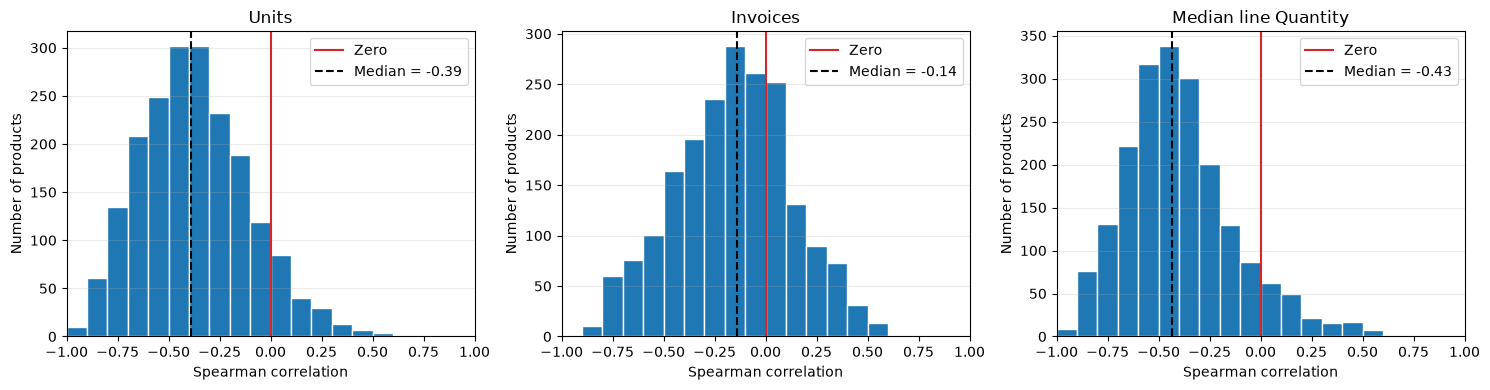

In [10]:
import matplotlib.pyplot as plt

part8a_outcomes = ("Units", "Invoices", "Median line Quantity")
part8a_figure, part8a_axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

for axis, outcome_name in zip(part8a_axes, part8a_outcomes):
    correlations = part7_correlations[("All product-weeks", outcome_name)].dropna()
    median_correlation = correlations.median()
    axis.hist(
        correlations,
        bins=np.linspace(-1, 1, 21),
        edgecolor="white",
    )
    axis.axvline(0, color="tab:red", linewidth=1.5, label="Zero")
    axis.axvline(
        median_correlation,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"Median = {median_correlation:.2f}",
    )
    axis.set_xlim(-1, 1)
    axis.set_title(outcome_name)
    axis.set_xlabel("Spearman correlation")
    axis.set_ylabel("Number of products")
    axis.legend()
    axis.grid(axis="y", alpha=0.25)

part8a_figure.tight_layout()
plt.show()

The panels show the distributions of the three all-product-week correlation series, with zero and each series' median marked. Limitation: correlations do not establish that price changes cause changes in the outcomes.

## 8b. How do weekly prices and invoice counts move together for selected products?

For the three products with the most active weeks in Part 7 and the eligible product with the most negative units correlation, what is the weekly relationship between `log(price_mode)` and `log(invoices)`?

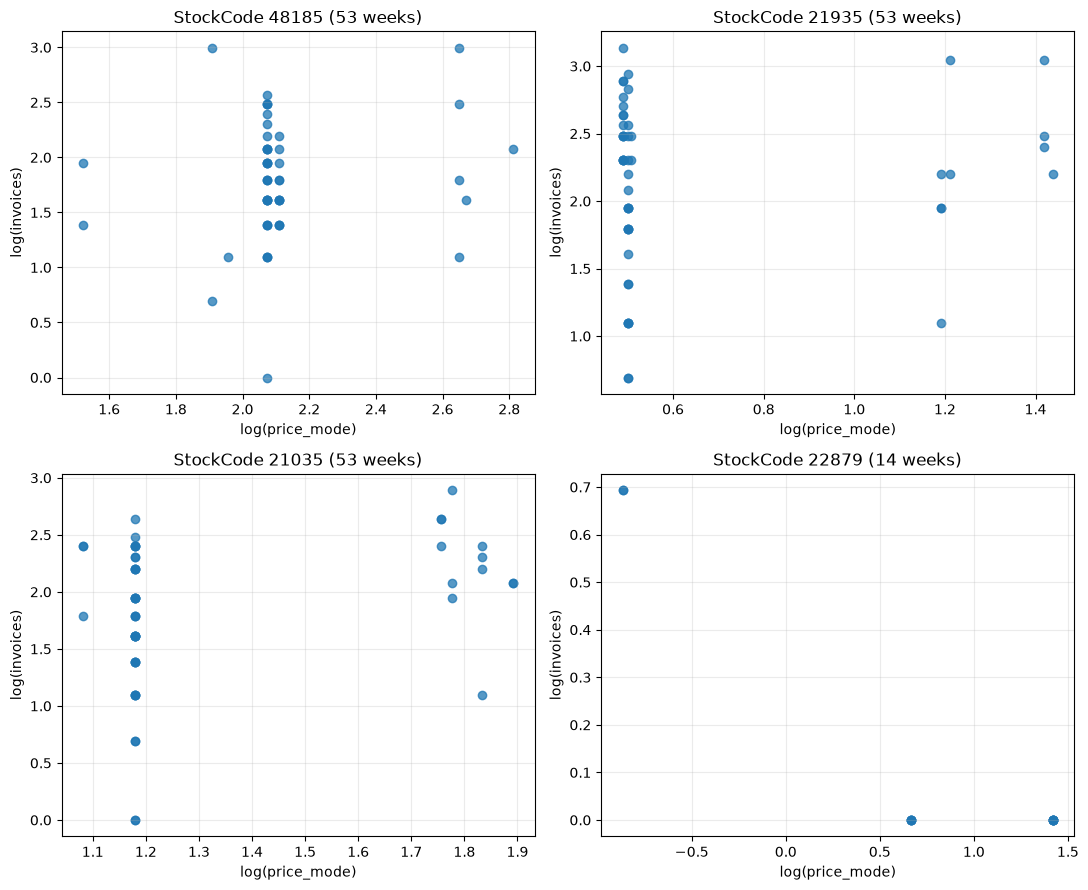

In [11]:
part8b_top_three = part7_top_products.head(3)["StockCode"].tolist()
part8b_units_correlations = part7_correlations[("All product-weeks", "Units")].dropna().sort_values()
part8b_negative_product = next(
    product
    for product in part8b_units_correlations.index
    if product not in part8b_top_three
)
part8b_products = [*part8b_top_three, part8b_negative_product]
part8b_weekly_rows = part7_samples["All product-weeks"]
part8b_figure, part8b_axes = plt.subplots(2, 2, figsize=(11, 9))

for axis, product in zip(part8b_axes.flat, part8b_products):
    product_rows = (
        part8b_weekly_rows.loc[part8b_weekly_rows["StockCode"].eq(product)]
        .sort_values("week")
    )
    assert product_rows["week"].is_unique
    assert product_rows["price_mode"].gt(0).all()
    assert product_rows["invoices"].gt(0).all()
    axis.scatter(
        np.log(product_rows["price_mode"]),
        np.log(product_rows["invoices"]),
        alpha=0.75,
    )
    axis.set_title(f"StockCode {product} ({len(product_rows)} weeks)")
    axis.set_xlabel("log(price_mode)")
    axis.set_ylabel("log(invoices)")
    axis.grid(alpha=0.25)

part8b_figure.tight_layout()
plt.show()

Each panel shows one weekly point per observed week for one selected product, plotting log modal price against log invoice count. Limitation: these descriptive product-level plots do not control for other factors that may affect invoices.